# Ласкаво просимо до Colab!

In [9]:

# Бібліотека для роботи з масивами
import numpy as np

# Бібліотека для побудови графіків
import matplotlib.pyplot as plt

# Набір рукописних цифр MNIST
from tensorflow.keras.datasets import mnist

# Бібліотека для створення нейромережі
from tensorflow import keras

# Шари нейронної мережі
from tensorflow.keras.layers import Dense, Flatten


In [10]:

# Завантажуємо навчальні та тестові дані MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Нормалізуємо значення пікселів від 0 до 1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Виводимо кількість зображень
print("Навчальних зображень:", len(x_train))
print("Тестових зображень:", len(x_test))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Навчальних зображень: 60000
Тестових зображень: 10000


In [11]:

# Перетворюємо цифри у вектори з 10 елементів
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Перевіряємо результат перетворення
print("Цифра:", y_train[0])
print("Вектор:", y_train_cat[0])


Цифра: 5
Вектор: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


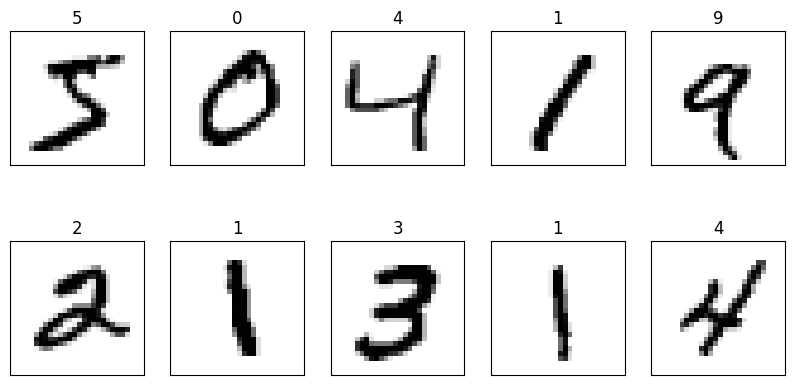

In [12]:

# Створюємо область для 10 зображень
plt.figure(figsize=(10, 5))

# Виводимо перші 10 навчальних цифр
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.title(str(y_train[i]))

# Показуємо зображення
plt.show()


In [13]:

# Створюємо послідовну нейронну мережу
model = keras.Sequential([

    # Перетворюємо зображення 28x28 у вектор
    keras.Input(shape=(28, 28)),
    Flatten(),

    # Прихований шар із 128 нейронами
    Dense(128, activation='relu'),

    # Вихідний шар для 10 цифр
    Dense(10, activation='softmax')
])

# Виводимо структуру моделі
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

# Налаштовуємо навчання нейромережі
model.compile(
    optimizer='adam',                    # Оптимізатор
    loss='categorical_crossentropy',     # Функція помилки
    metrics=['accuracy']                 # Точність
)


In [15]:

# Навчаємо модель протягом 7 епох
history = model.fit(
    x_train,
    y_train_cat,
    batch_size=32,          # По 32 зображення
    epochs=7,              # 7 епох для 14 варіанта
    validation_split=0.2   # 20% даних для перевірки
)


Epoch 1/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9186 - loss: 0.2854 - val_accuracy: 0.9544 - val_loss: 0.1567
Epoch 2/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9620 - loss: 0.1307 - val_accuracy: 0.9656 - val_loss: 0.1181
Epoch 3/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9728 - loss: 0.0886 - val_accuracy: 0.9685 - val_loss: 0.1056
Epoch 4/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9798 - loss: 0.0673 - val_accuracy: 0.9726 - val_loss: 0.0891
Epoch 5/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9837 - loss: 0.0514 - val_accuracy: 0.9702 - val_loss: 0.0959
Epoch 6/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9881 - loss: 0.0398 - val_accuracy: 0.9746 - val_loss: 0.0854
Epoch 7/7
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9905 - loss: 0.0311 - val_accuracy: 0.9750 - val_loss: 0.0851


In [16]:

# Перевіряємо модель на тестових даних
loss, accuracy = model.evaluate(x_test, y_test_cat)

# Виводимо точність у відсотках
print("Точність нейромережі:", accuracy * 100, "%")
print("Помилка:", loss)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9771 - loss: 0.0729
Точність нейромережі: 97.71000146865845 %
Помилка: 0.07289142161607742


Ймовірності: [[1.3496369e-06 4.7533191e-03 9.7194119e-05 8.5957106e-03 4.2570516e-09
  9.8508584e-01 2.5526749e-06 3.5231466e-07 1.4573203e-03 6.3282546e-06]]
Розпізнана цифра: 5
Правильна цифра: 5


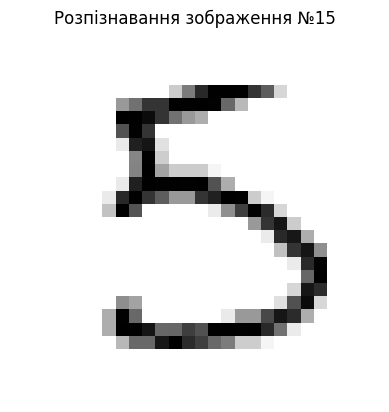

In [17]:

# Номер зображення для 14 варіанта
n = 15

# Готуємо зображення для нейромережі
x = np.expand_dims(x_test[n], axis=0)

# Отримуємо прогноз
res = model.predict(x, verbose=0)

# Виводимо ймовірності для всіх цифр
print("Ймовірності:", res)

# Визначаємо розпізнану цифру
print("Розпізнана цифра:", np.argmax(res))

# Виводимо правильну відповідь
print("Правильна цифра:", y_test[n])

# Показуємо зображення
plt.imshow(x_test[n], cmap=plt.cm.binary)
plt.title("Розпізнавання зображення №15")
plt.axis('off')
plt.show()


In [18]:

# Розпізнаємо всі тестові зображення
pred = model.predict(x_test)

# Вибираємо цифру з найбільшою ймовірністю
pred = np.argmax(pred, axis=1)

# Виводимо кількість прогнозів
print(pred.shape)

# Перші 10 прогнозів нейромережі
print("Прогнози:", pred[:10])

# Перші 10 правильних відповідей
print("Правильні:", y_test[:10])


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(10000,)
Прогнози: [7 2 1 0 4 1 4 9 5 9]
Правильні: [7 2 1 0 4 1 4 9 5 9]


In [19]:

# Порівнюємо прогнози з правильними цифрами
mask = pred == y_test

# Показуємо перші 10 результатів порівняння
print(mask[:10])

# Вибираємо неправильно розпізнані зображення
x_false = x_test[~mask]

# Зберігаємо неправильні прогнози
p_false = pred[~mask]

# Зберігаємо правильні відповіді
y_false = y_test[~mask]

# Виводимо кількість помилок
print("Кількість помилок:", len(x_false))


[ True  True  True  True  True  True  True  True  True  True]
Кількість помилок: 229


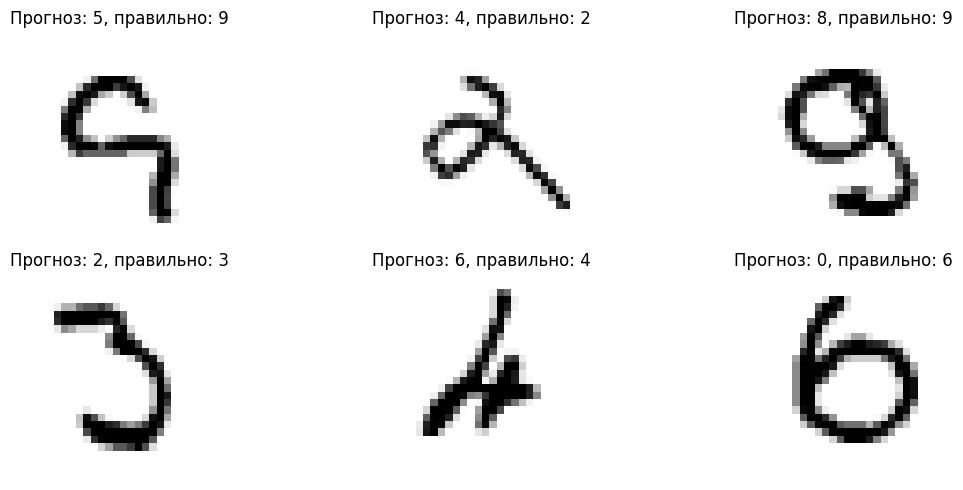

In [20]:

# Для 14 варіанта показуємо 6 помилок
plt.figure(figsize=(12, 5))

# Виводимо перші 6 неправильних зображень
for i in range(6):
    plt.subplot(2, 3, i + 1)

    # Показуємо зображення
    plt.imshow(x_false[i], cmap=plt.cm.binary)

    # Виводимо прогноз і правильну цифру
    plt.title(f"Прогноз: {p_false[i]}, правильно: {y_false[i]}")

    # Приховуємо осі
    plt.axis('off')

# Відображаємо всі зображення
plt.tight_layout()
plt.show()


**Висновок**

Під час виконання лабораторної роботи я ознайомилася з процесом розпізнавання рукописних цифр за допомогою повнозв'язної нейронної мережі. Для роботи використала бібліотеки TensorFlow та Keras і набір даних MNIST.

Відповідно до свого 14 варіанта я створила нейронну мережу з прихованим шаром із 128 нейронів та виконала її навчання протягом 7 епох. Також передбачила перевірку точності моделі на тестових даних, розпізнавання зображення з номером 15 та візуалізацію 6 неправильно розпізнаних зображень.

У результаті я закріпила навички створення, навчання та тестування нейронних мереж, а також навчилася аналізувати результати їхньої роботи.